# Détection d'attaques ADS-B en direct (OpenScope-sec) : non supervisé vs supervisé

Deux détecteurs, mêmes variables physiques calculées sur chaque message ADS-B :

| Modèle | Apprend sur | Idée |
|---|---|---|
| **Non supervisé** (`detecteur_adsb.py`) | trafic normal uniquement | enveloppe du vol normal ; tout ce qui en sort est une alerte |
| **Supervisé** (`supervise_adsb.py`) | exemples des 3 attaques + normal | forêt aléatoire qui prédit le type d'attaque |

**Pendant la démo**
1. Lancer l'attaque dans OpenScope-sec, puis cliquer **Download ads-b** (le CSV de *tous* les avions).
2. Mettre le chemin du fichier dans `CSV_LIVE` (cellule 1).
3. Exécuter les cellules 1, 3, 4 et 5. Les modèles sont déjà entraînés (`modeles/`) ; la cellule 2 ne sert qu'à les réentraîner.

Installation : `pip install -r requirements.txt`

In [1]:
# Cellule 1 : paramètres
%matplotlib inline
import os
import pandas as pd
from IPython.display import display, Markdown
import detecteur_adsb as NS          # non supervisé
import supervise_adsb as SUP         # supervisé
import evaluation_adsb as EV
import experiences as XP

CSV_LIVE  = "data/capture_B0_test.csv.gz"   # <- remplacer par le fichier fraîchement téléchargé
AVION     = None                            # ex. "aircraft-9461" ; None = l'avion le plus anormal
MODELE_NS = "modeles/modele_normal.json"
MODELE_S  = "modeles/modele_supervise.joblib"
REENTRAINER = False                          # True : refaire l'apprentissage (cellule 2)

In [2]:
# Cellule 2 : (optionnel) réentraîner les deux modèles sur les captures d'entraînement
if REENTRAINER or not (os.path.exists(MODELE_NS) and os.path.exists(MODELE_S)):
    F = NS.charger(XP.ENTRAINEMENT)
    NS.entrainer(F, MODELE_NS)
    SUP.entrainer(EV.verite_terrain(F), MODELE_S)
m_ns = NS.charger_modele(MODELE_NS)
m_s  = SUP.charger_modele(MODELE_S)
NS.afficher_modele(m_ns)
print("Supervisé appris sur :", m_s["apprentissage"]["par_classe"])

Appris sur 346 avions / 195037 messages normaux en vol.
  pas_norm   normal dans [0.80 ; 1.20]   (vu en normal : [0.927, 1.0545])
  fige_run   alerte à partir de 3 messages immobiles   (vu en normal : 0)
  d_cap      alerte au-dessus de 0.55   (vu en normal : max 0.3633)
  d_alt      alerte au-dessus de 100 ft/message   (vu en normal : max 27.22)
  cap_abs    alerte au-dessus de 3.00°   (vu en normal : max 1.997°)
Supervisé appris sur : {'No attack': 195037, 'Trajectory modification': 28934, 'Aircraft standing still': 2647, 'Jumping aircraft': 295}


In [3]:
# Cellule 3 : détection sur la capture (les deux modèles)
capture = NS.charger(CSV_LIVE)                 # variables calculées une seule fois
res_ns = NS.detecter(capture, m_ns)
res_s  = SUP.detecter(capture, m_s)

for nom, r in [("Non supervisé", res_ns), ("Supervisé", res_s)]:
    al = r[r.alerte]
    print(f"{nom:14s}: {int(r.alerte.sum()):6d} messages en alerte, {al.id.nunique():3d} avions concernés "
          f"sur {r.id.nunique()} ; types : {al.prediction.value_counts().to_dict()}")

resume = NS.resume_par_avion(res_ns)
resume["type (supervisé)"] = res_s[res_s.alerte].groupby("id").prediction.agg(lambda s: s.mode().iloc[0])
resume["alertes (supervisé)"] = res_s.groupby("id").alerte.sum()
display(resume[(resume.alertes > 0) | (resume["alertes (supervisé)"] > 0)].head(15))

Non supervisé :  30428 messages en alerte, 143 avions concernés sur 301 ; types : {'Trajectory modification': 22540, 'Aircraft standing still': 7617, 'Jumping aircraft': 271}
Supervisé     :  31397 messages en alerte, 143 avions concernés sur 301 ; types : {'Trajectory modification': 23530, 'Aircraft standing still': 7596, 'Jumping aircraft': 271}


,callsign,messages,en_vol,alertes,1re_alerte_msg,score_max,type_probable,motifs,etiquette,type (supervisé),alertes (supervisé)
id,,,,,,,,,,,
aircraft-1300,UAL8,1495,1473,1155,319.0,40.00,Aircraft standing still,avion figé,Aircraft standing still,Aircraft standing still,1154
aircraft-1260,ASA547,1415,1393,1112,151.0,7.29,Trajectory modification,cap incohérent,Trajectory modification,Trajectory modification,1248
aircraft-1280,BAW148,1413,1391,1110,151.0,7.33,Trajectory modification,cap incohérent,Trajectory modification,Trajectory modification,1122
aircraft-9452,SKW4921,1114,1092,1087,6.0,9.02,Trajectory modification,cap incohérent,Trajectory modification,Trajectory modification,1089
aircraft-9465,BAW66P,1140,1118,1075,6.0,9.17,Trajectory modification,cap incohérent,Trajectory modification,Trajectory modification,1078
aircraft-1272,QXE2127,1323,1301,1020,151.0,7.33,Trajectory modification,cap incohérent,Trajectory modification,Trajectory modification,1032
aircraft-9495,ASA5174,1067,1045,1004,4.0,9.17,Trajectory modification,cap incohérent,Trajectory modification,Trajectory modification,1007
aircraft-1212,TSA6991,1495,1473,1002,472.0,40.00,Aircraft standing still,avion figé; cap incohérent,Aircraft standing still,Aircraft standing still,1002
aircraft-9469,SWA9315,1003,981,977,5.0,8.86,Trajectory modification,cap incohérent,Trajectory modification,Trajectory modification,979


In [4]:
# Cellule 4 : évaluation (seulement si le CSV contient les étiquettes du simulateur)
if (capture.attackType != NS.NORMAL).any():
    t = EV.verite_terrain(capture)
    t["pred_non_supervise"] = res_ns.prediction.values
    t["pred_supervise"] = res_s.prediction.values
    display(Markdown("**Tableau comparatif** (vérité terrain effective, voir `evaluation_adsb.py`)"))
    display(XP.tableau_comparatif(t).round(3))
    for col, nom in [("pred_non_supervise", "Non supervisé"), ("pred_supervise", "Supervisé")]:
        display(Markdown(f"**Matrice de confusion : {nom}** (lignes = vérité, colonnes = prédiction)"))
        display(EV.matrice_confusion(t, col))
else:
    print("Pas d'étiquettes d'attaque dans ce CSV : seules les alertes sont affichées.")

**Tableau comparatif** (vérité terrain effective, voir `evaluation_adsb.py`)

,modèle,attaque,précision,rappel,F1,avions détectés (effet),avions détectés (étiquette brute),retard médian (msgs),fausses alertes / 1000 msgs normaux,avions normaux avec fausse alerte
0,Non supervisé (enveloppe normale),Jumping,0.940,1.000,0.969,51/51,92/203,0.0,NaN,NaN
1,Non supervisé (enveloppe normale),Standing still,0.976,1.000,0.988,22/22,22/60,0.0,NaN,NaN
2,Non supervisé (enveloppe normale),VTM,1.000,0.939,0.969,83/83,83/83,4.0,NaN,NaN
3,Non supervisé (enveloppe normale),Toute attaque (binaire),0.999,0.957,0.977,,,NaN,2.733,2/27
4,Supervisé (forêt aléatoire),Jumping,0.940,1.000,0.969,51/51,89/203,0.0,NaN,NaN
5,Supervisé (forêt aléatoire),Standing still,0.976,1.000,0.988,22/22,22/60,0.0,NaN,NaN
6,Supervisé (forêt aléatoire),VTM,1.000,0.967,0.983,83/83,83/83,2.0,NaN,NaN
7,Supervisé (forêt aléatoire),Toute attaque (binaire),0.999,0.979,0.989,,,NaN,2.733,2/27


**Matrice de confusion : Non supervisé** (lignes = vérité, colonnes = prédiction)

prédit,Normal,Jumping,Standing still,VTM
vérité,,,,
Normal,11676,0,32,0
Jumping,0,251,0,0
Standing still,0,0,6189,0
VTM,1306,16,120,22237


**Matrice de confusion : Supervisé** (lignes = vérité, colonnes = prédiction)

prédit,Normal,Jumping,Standing still,VTM
vérité,,,,
Normal,11676,0,32,0
Jumping,0,251,0,0
Standing still,0,0,6189,0
VTM,642,16,119,22902


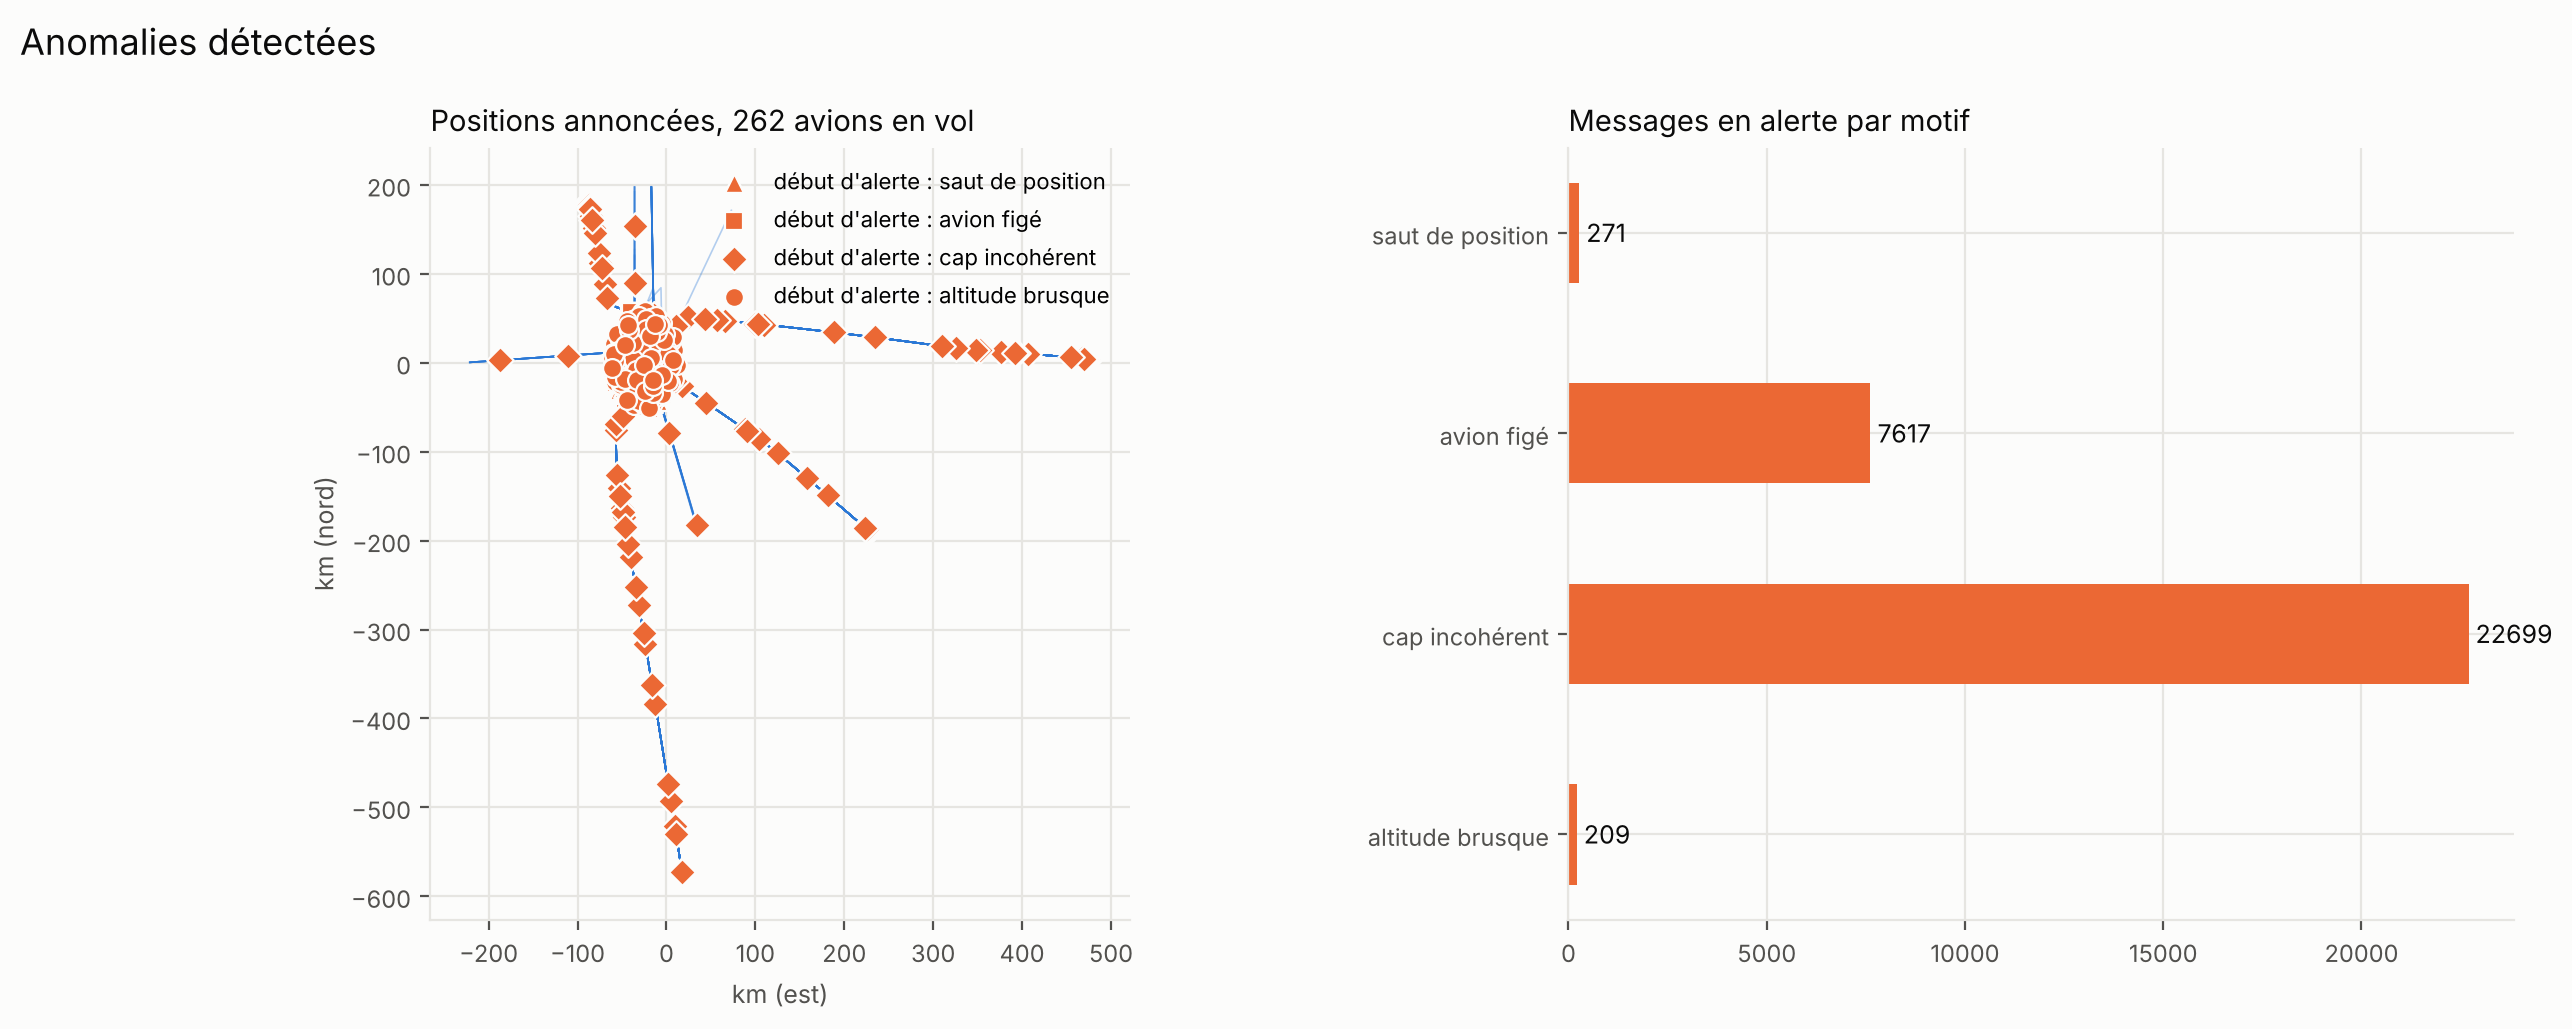

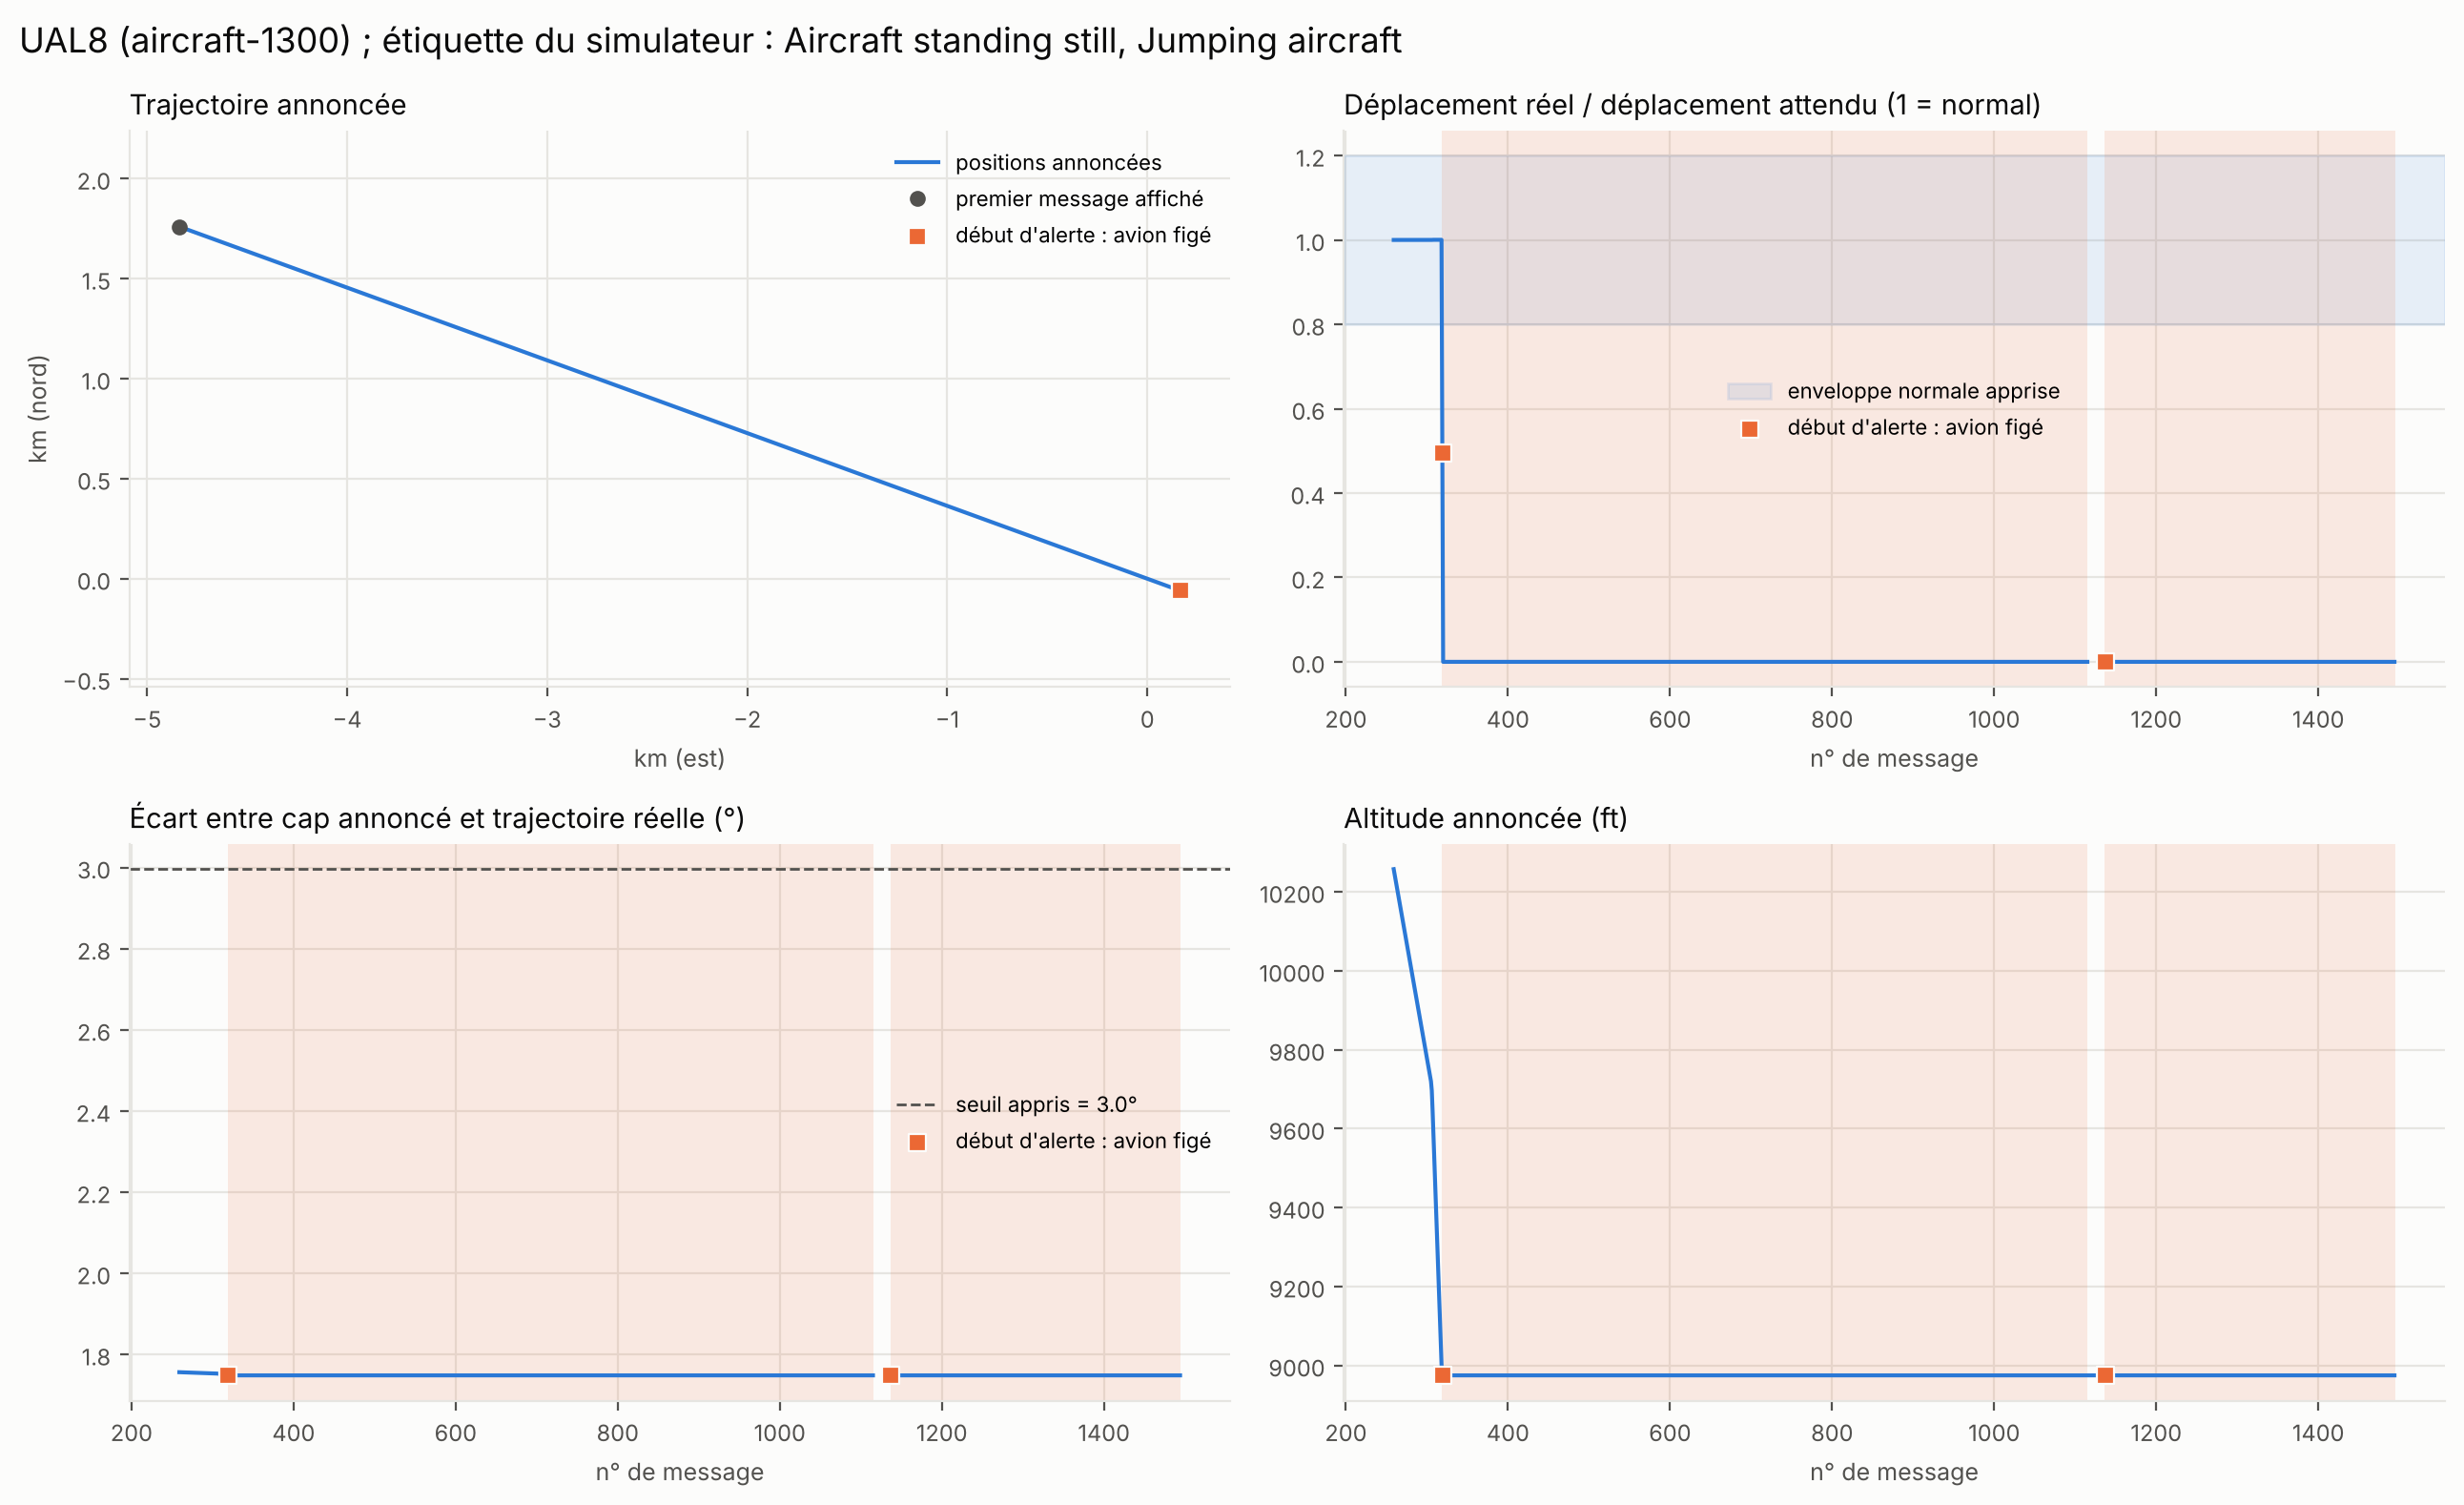

In [5]:
# Cellule 5 : graphiques (non supervisé : il explique POURQUOI chaque alerte est levée)
NS.tracer_vue_ensemble(res_ns)
cible = AVION or (resume.index[0] if resume.alertes.iloc[0] > 0 else None)
if cible:
    NS.tracer_avion(res_ns, cible, m_ns)